# 지하철 이용승객 분석 EDA


## 0. 라이브러리 불러오기

In [1]:
import sys, subprocess

def _ensure(pkg):
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg])

for _pkg in ['pandas', 'matplotlib', 'seaborn', 'folium']:
    _ensure(_pkg)

import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 깨짐 방지 (윈도우 기준, Mac은 'AppleGothic')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


## 1. 데이터 불러오고 합치기

In [2]:
dirpath = './rawfiles/'
files = [f for f in os.listdir(dirpath) if f.startswith('CARD_SUBWAY')]
print(files)  # 어떤 파일들을 읽는지 확인

raw = pd.DataFrame()
for f in files:
    temp = pd.read_csv(dirpath + f, encoding='utf-8')  # 파일이 안 열리면 encoding='cp949'로 바꿔보세요
    raw = pd.concat([raw, temp], axis=0)

raw = raw.reset_index(drop=True)
raw.info()


['CARD_SUBWAY_MONTH_201901.csv', 'CARD_SUBWAY_MONTH_201902.csv', 'CARD_SUBWAY_MONTH_201903.csv', 'CARD_SUBWAY_MONTH_201904.csv', 'CARD_SUBWAY_MONTH_201905.csv', 'CARD_SUBWAY_MONTH_201906.csv']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107028 entries, 0 to 107027
Data columns (total 6 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   사용일자    107028 non-null  int64  
 1   노선명     107028 non-null  object 
 2   역명      107028 non-null  object 
 3   승차총승객수  107028 non-null  float64
 4   하차총승객수  107028 non-null  float64
 5   등록일자    107028 non-null  int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 4.9+ MB


In [3]:
raw.head()

,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자
0,20190101,2호선,을지로4가,3862.0,3728.0,20190104
1,20190101,3호선,을지로3가,8104.0,7554.0,20190104
2,20190101,2호선,을지로입구,22478.0,21330.0,20190104
3,20190101,2호선,시청,8381.0,6049.0,20190104
4,20190101,6호선,동묘앞,8045.0,8504.0,20190104


## 2. Feature Engineering: 요일 / 연월 / 월일 / 승하차총승객수 컬럼 추가
- 매핑 변경
`{0:'일', 1:'월', ...}` --> `{0:'월', ...6:'일'}`

In [4]:
raw['사용일자'] = pd.to_datetime(raw['사용일자'], format='%Y%m%d')

# 요일 (0=월요일 ~ 6=일요일 이므로 매핑도 그렇게)
conv = {0:'월', 1:'화', 2:'수', 3:'목', 4:'금', 5:'토', 6:'일'}
raw['요일'] = raw['사용일자'].dt.dayofweek.map(conv)

# 연월 / 월일
raw['연월'] = raw['사용일자'].dt.strftime('%Y-%m')
raw['월일'] = raw['사용일자'].dt.strftime('%m-%d')

# 승하차 합계
raw['승하차총승객수'] = raw['승차총승객수'] + raw['하차총승객수']

raw = raw[['사용일자','요일','노선명','역명','승차총승객수','하차총승객수','승하차총승객수','연월','월일','등록일자']]
raw.sample(5)


,사용일자,요일,노선명,역명,승차총승객수,하차총승객수,승하차총승객수,연월,월일,등록일자
94975,2019-06-10,월,1호선,배방,1119.0,1108.0,2227.0,2019-06,06-10,20190613
20483,2019-02-04,월,4호선,대공원,3347.0,3322.0,6669.0,2019-02,02-04,20190207
66176,2019-04-22,월,9호선,신목동,4619.0,4212.0,8831.0,2019-04,04-22,20190425
4882,2019-01-09,수,1호선,천안,5207.0,5313.0,10520.0,2019-01,01-09,20190112
64451,2019-04-19,금,우이신설경전철,삼양,2433.0,2612.0,5045.0,2019-04,04-19,20190422


In [5]:
# 정리한 데이터 저장
raw.to_csv('./subway_raw.csv', index=False, encoding='utf-8-sig')


## Q1) 2019.01~06 중 언제 지하철을 가장 많이 이용했을까? (기준: 승하차총승객수)
## Q2, 가설) 1~6월 중 5월에 승객수가 많다?

연월
2019-01    442746389.0
2019-02    379836010.0
2019-03    466692826.0
2019-04    470934348.0
2019-05    485718557.0
2019-06    442210635.0
Name: 승하차총승객수, dtype: float64


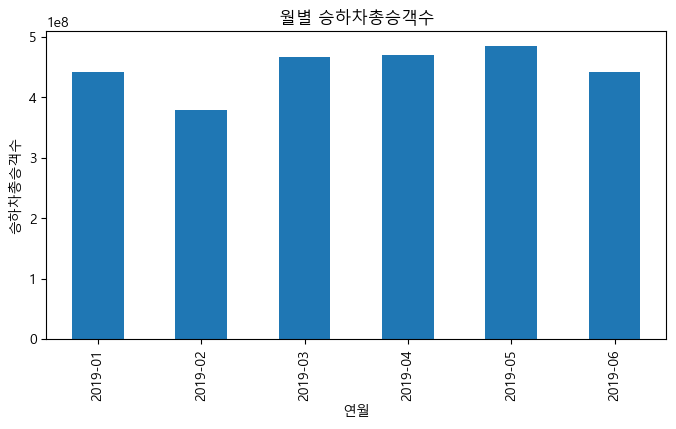

In [6]:
monthly = raw.groupby('연월')['승하차총승객수'].sum()
print(monthly)

monthly.plot(kind='bar', figsize=(8,4), title='월별 승하차총승객수')
plt.ylabel('승하차총승객수')
plt.show()


### 해석
- 참.
- 5월에 승객수가 가장 많다.
- '가정의 달'로 휴일이 많아 이동이 많을 것으로 추정된다.

## Q3, 가설) 요일 중 목요일에 승객수가 많다?

요일
월    391555551.0
화    411979965.0
수    421134136.0
목    428684383.0
금    445310717.0
토    341950018.0
일    247523995.0
Name: 승하차총승객수, dtype: float64


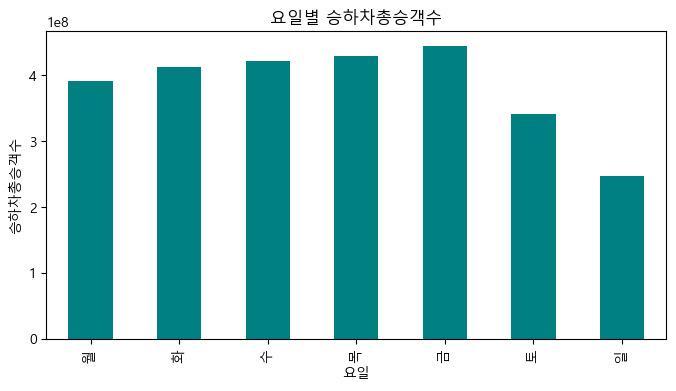

In [7]:
weekday_order = ['월','화','수','목','금','토','일']
by_weekday = raw.groupby('요일')['승하차총승객수'].sum().reindex(weekday_order)
print(by_weekday)

by_weekday.plot(kind='bar', figsize=(8,4), title='요일별 승하차총승객수', color='teal')
plt.ylabel('승하차총승객수')
plt.show()


### 해석
- 거짓.
- 금요일에 승객수가 가장 많다.
- 주말을 앞두고 본가로 돌아가는 학생/직장인이 많을 것으로 예상된다.

## Q4) 연월 각각에 대해 일자별(월일별) 승하차총승객수 그래프를 그려보자 (pointplot)

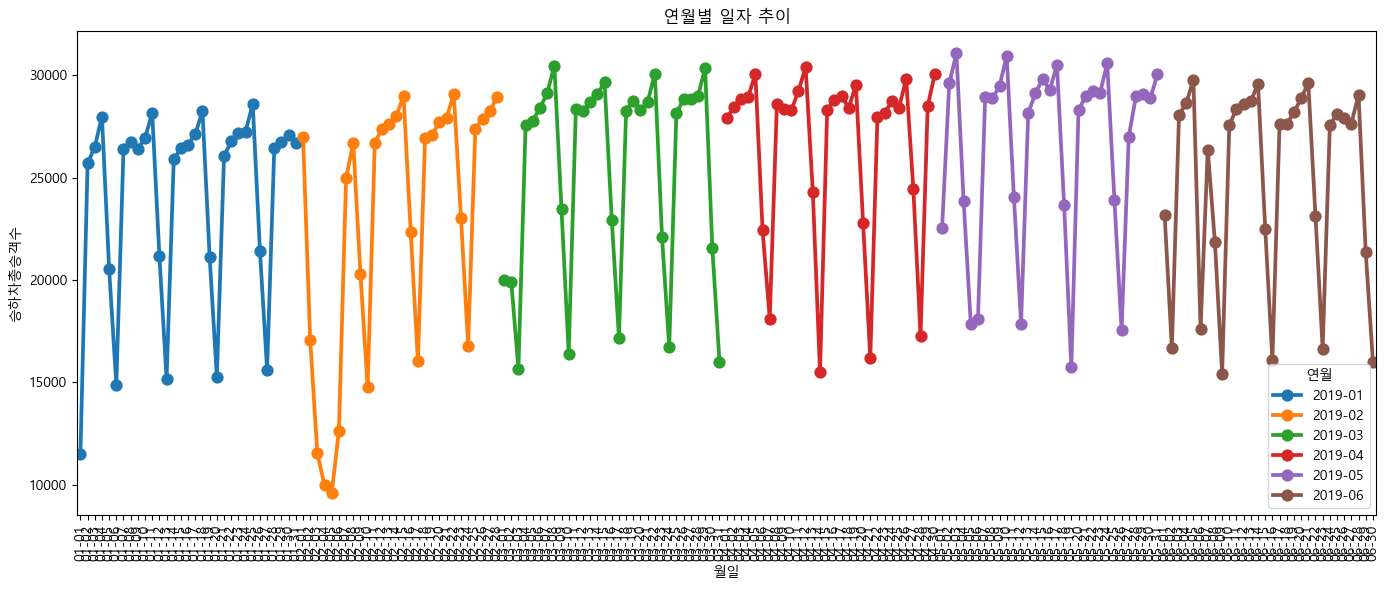

In [8]:
plt.figure(figsize=(14,6))
sns.pointplot(data=raw, x='월일', y='승하차총승객수', hue='연월', errorbar=None)
plt.xticks(rotation=90)
plt.title('연월별 일자 추이')
plt.tight_layout()
plt.show()


### 해석
- 2월에 독특하게 아래로 튀는 양상이 보인다.
- 2월의 설연휴의 영향으로 예상된다.

## Q5) 가장 승객이 많이 타는 승차역은?

역명
잠실         18574323.0
강남         18148024.0
고속터미널      17541287.0
홍대입구       17270084.0
서울역        17165598.0
사당         13294251.0
신림         12831374.0
선릉         11582155.0
구로디지털단지    11421335.0
신도림        11420882.0
Name: 승차총승객수, dtype: float64


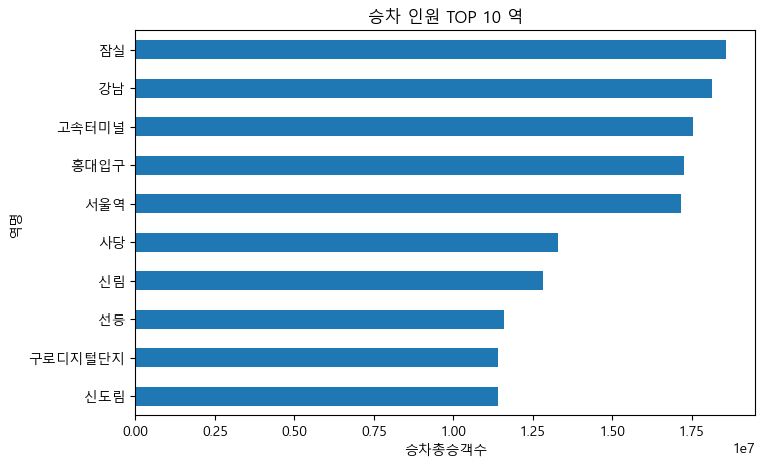

In [9]:
top_stations = raw.groupby('역명')['승차총승객수'].sum().sort_values(ascending=False)
print(top_stations.head(10))

top_stations.head(10).plot(kind='barh', figsize=(8,5))
plt.gca().invert_yaxis()
plt.title('승차 인원 TOP 10 역')
plt.xlabel('승차총승객수')
plt.show()


### 해석
- 잠실: 주거지역, 상업시설, 2·8호선 환승, 버스
- 강남: 업무지구, 상업시설, 2호선 중심지, 버스 환승
- 고속터미널: 3·7·9호선 환승, 고속버스터미널, 상업시설
- 홍대입구: 홍대 상권, 관광·여가시설, 2호선·공항철도·경의중앙선 환승
- 서울역: KTX·광역철도, 1·4호선 환승, 업무·관광 중심지
- 사당: 2·4호선 환승, 경기 남부권과 서울 연결, 버스 환승
- 신림: 대규모 주거지역, 상권, 2호선·신림선 환승
- 선릉: 강남 업무지구, 2호선·수인분당선 환승, 직장인 통근
- 구로디지털단지: IT·벤처 업무지구, 2호선, 직장인 통근
- 신도림: 1·2호선 환승, 서울·경기·인천 연결, 주거·상업시설

## Q6) 노선별로 역별/요일별 승차승객수를 비교해 볼 수 있을까? (heatmap)

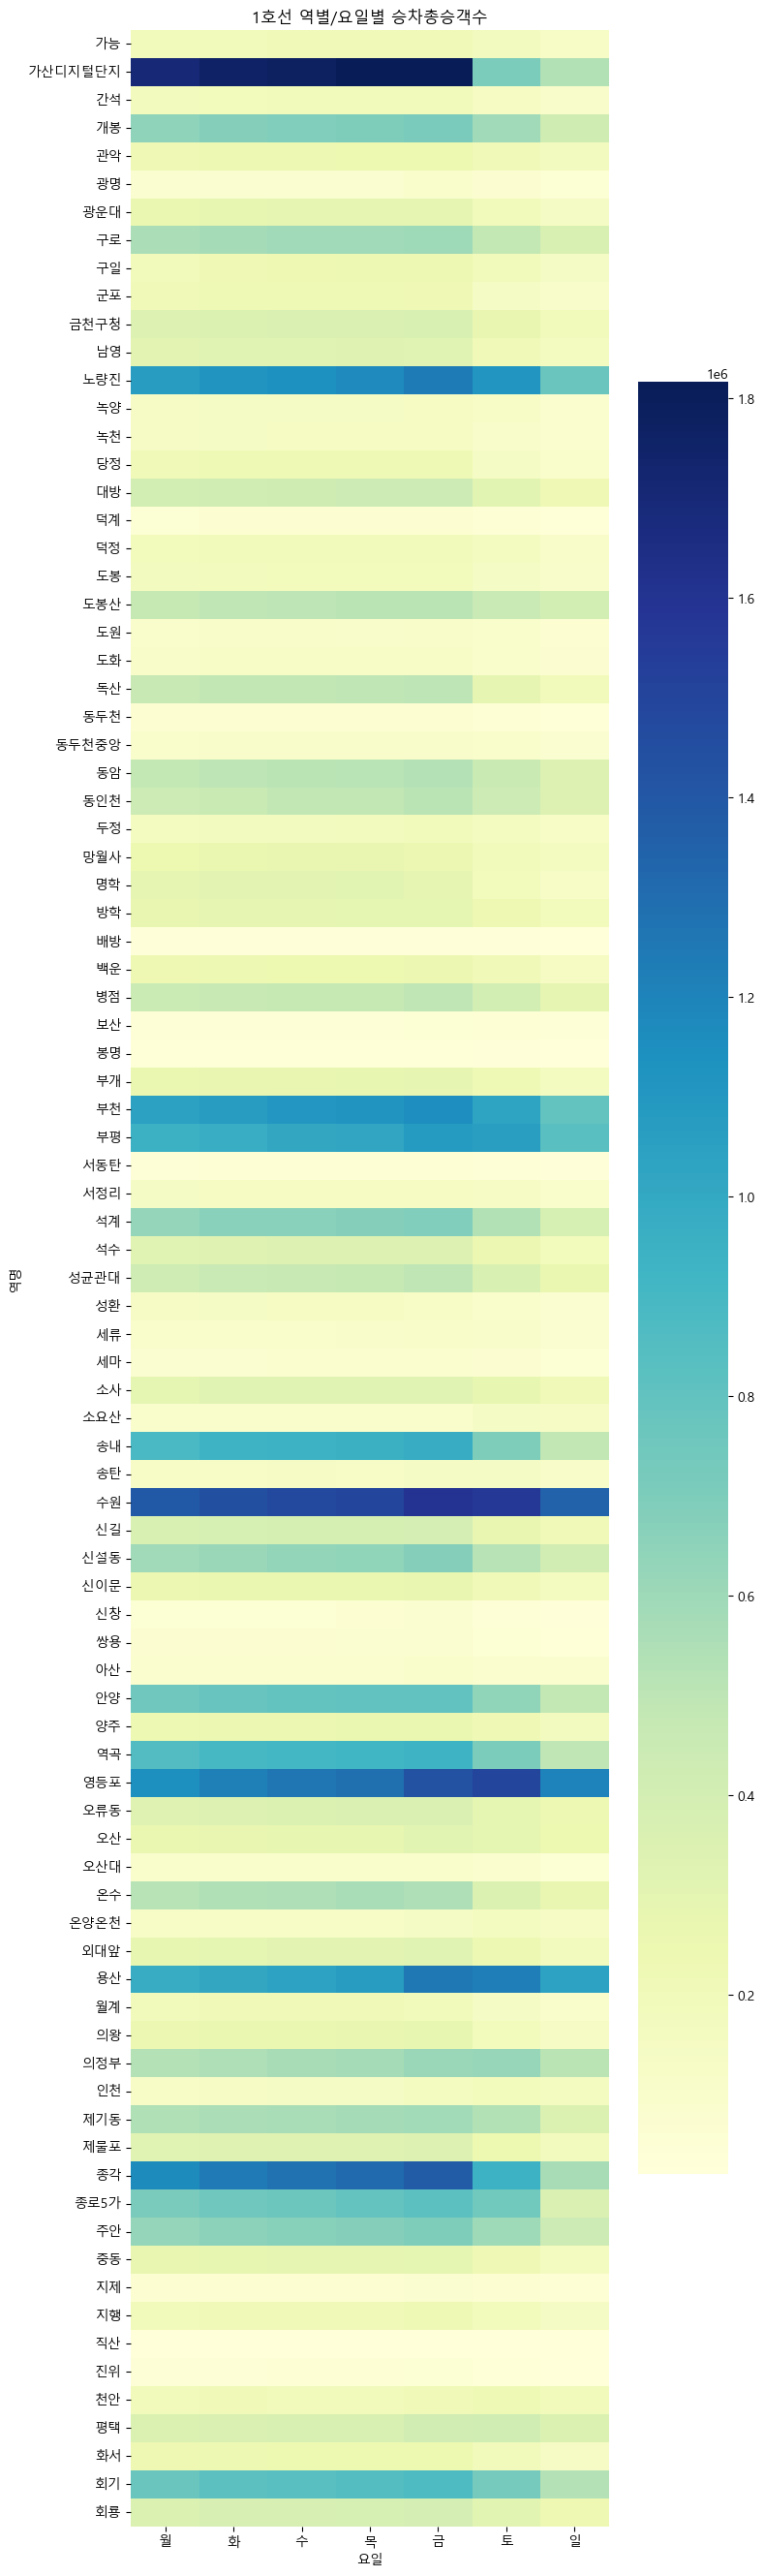

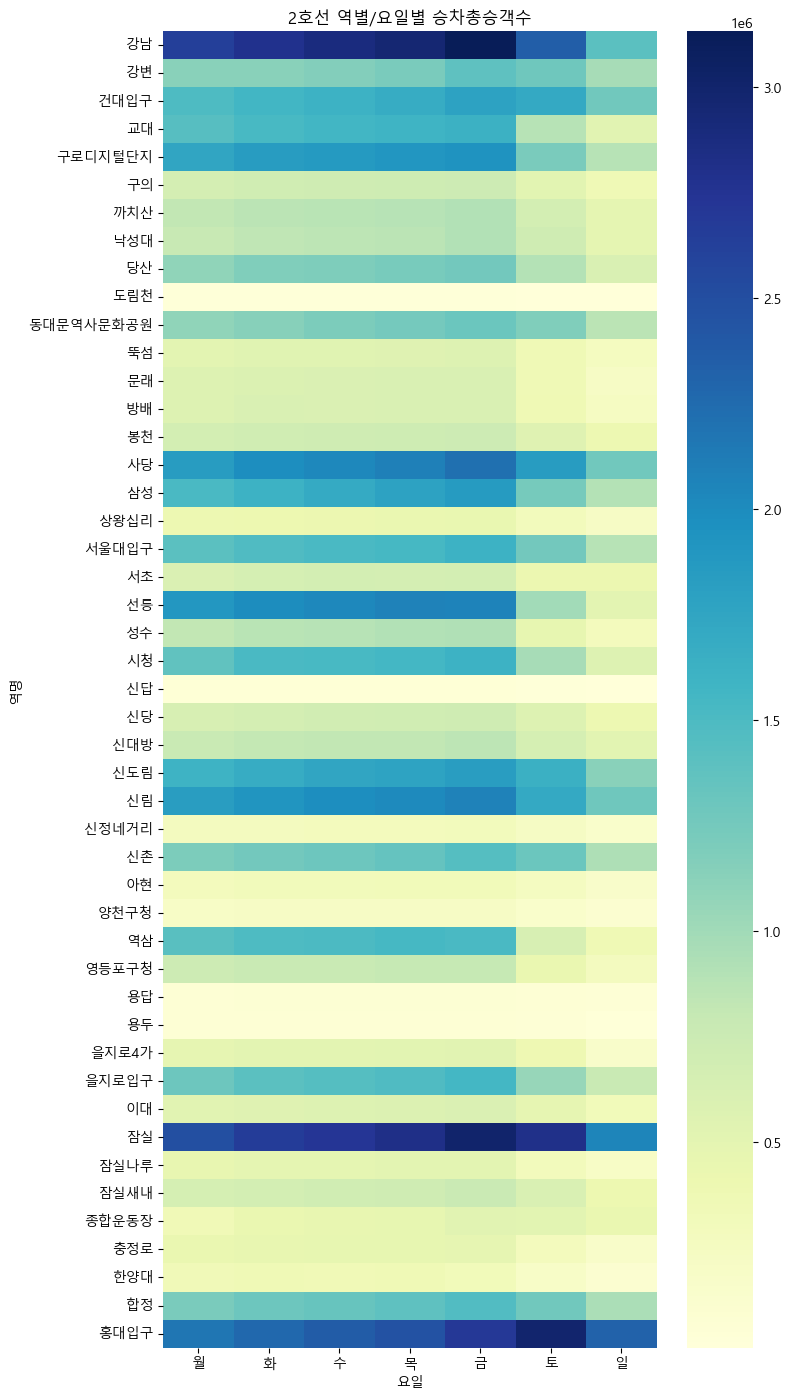

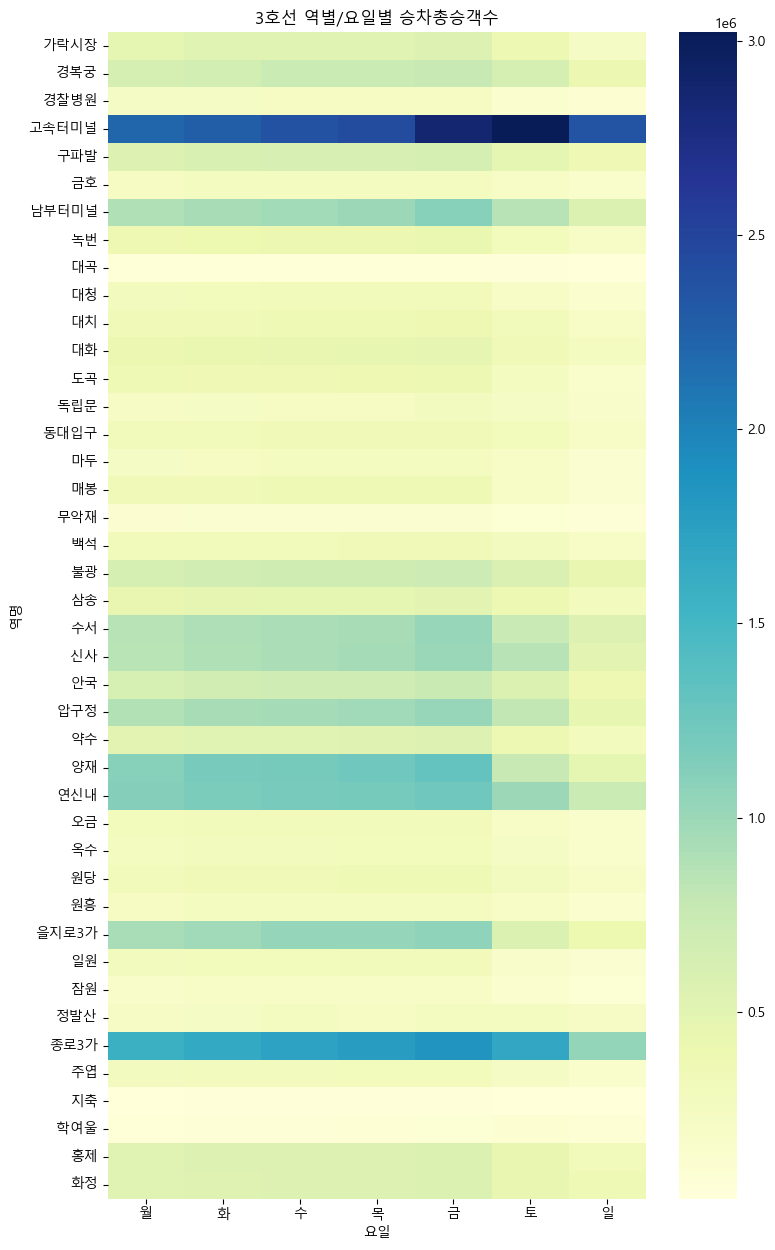

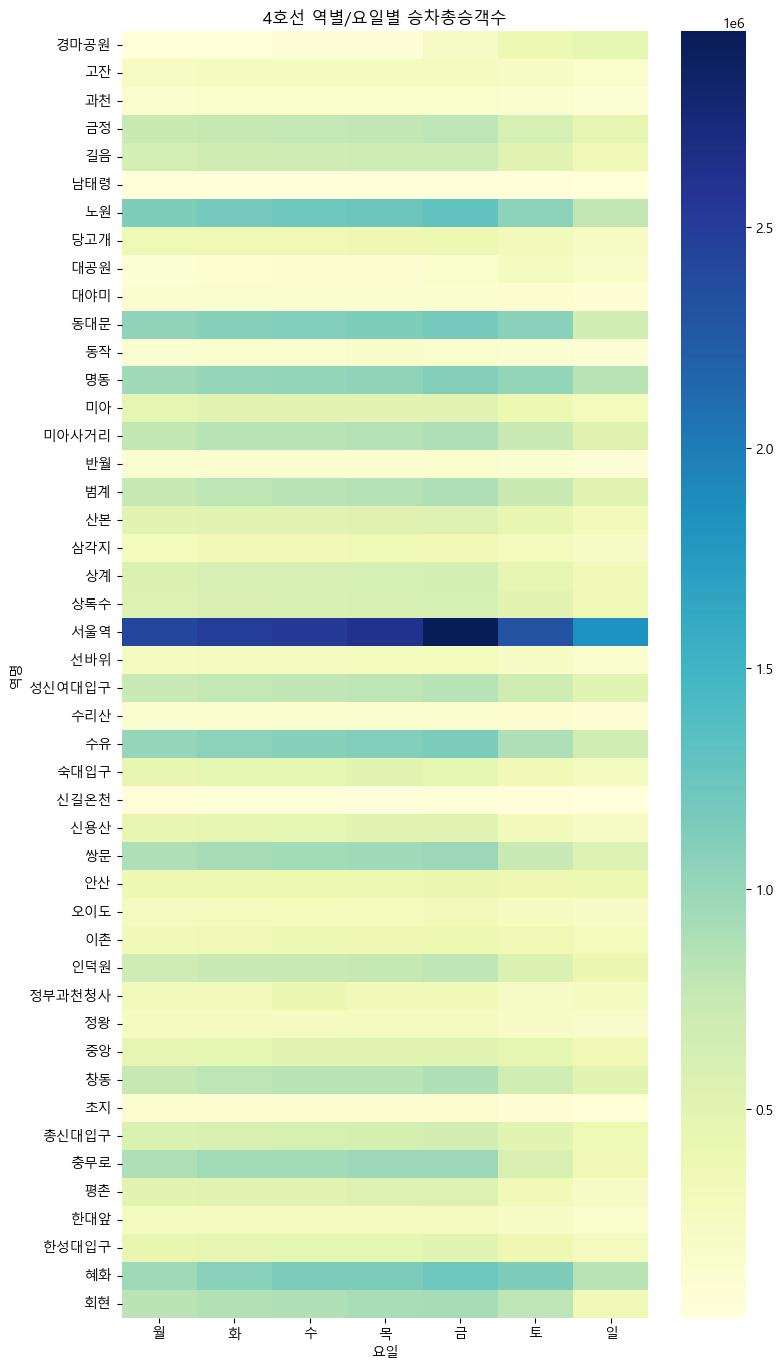

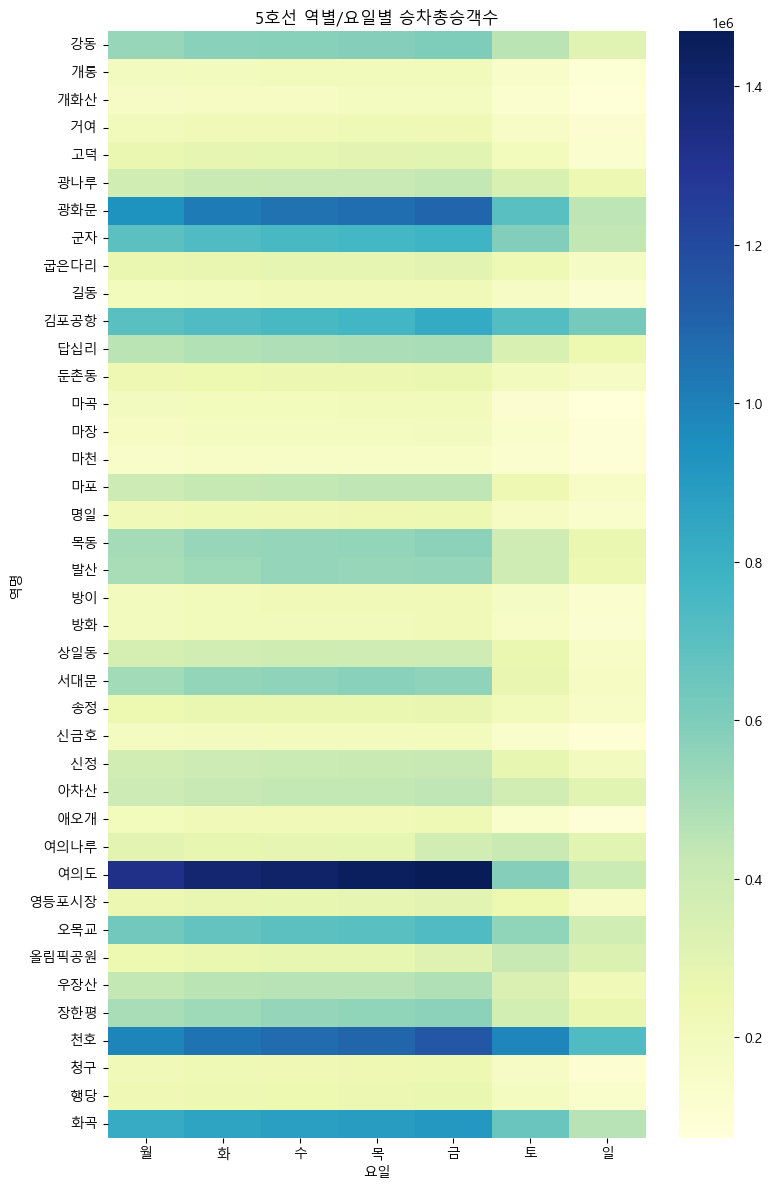

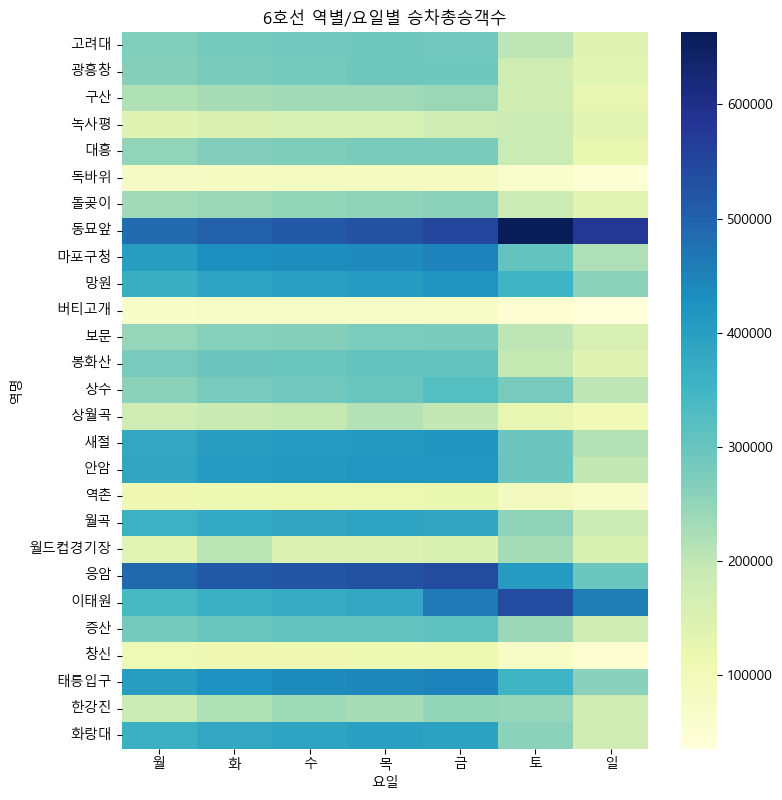

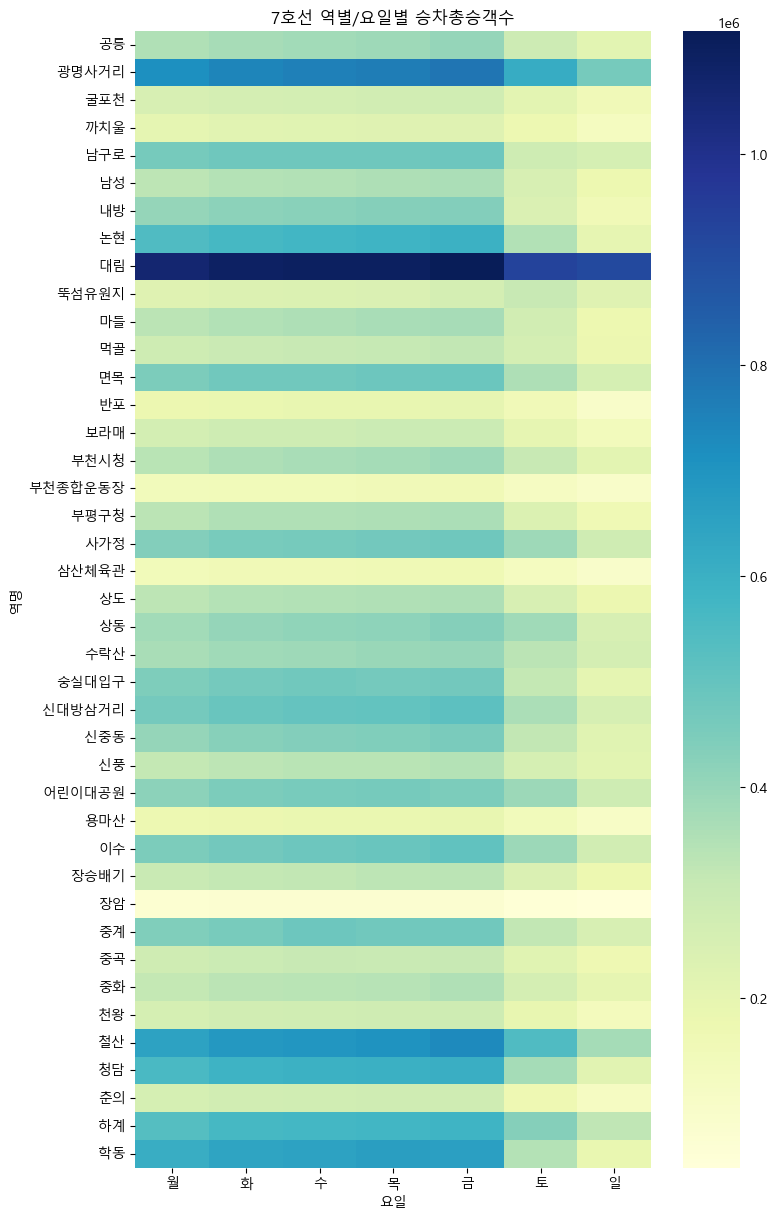

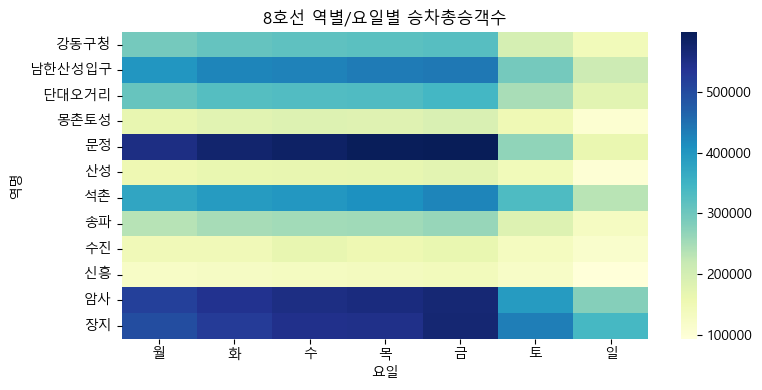

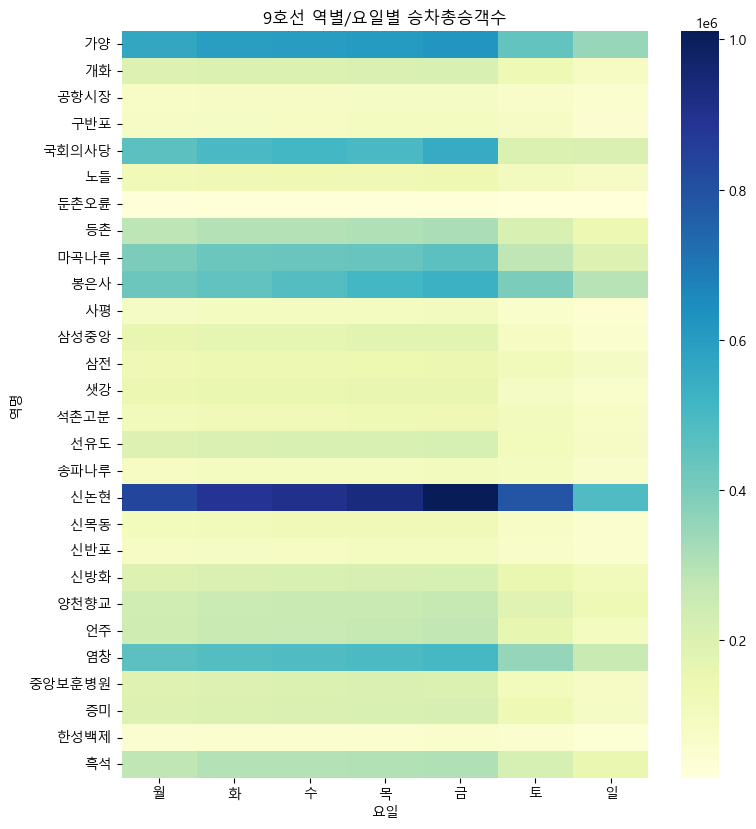

In [10]:
for i in range(1, 10):
    line = f'{i}호선'
    target = raw[raw['노선명'] == line]
    if target.empty:
        continue

    pivot = target.pivot_table(index='역명', columns='요일', values='승차총승객수', aggfunc='sum')
    pivot = pivot[weekday_order]

    plt.figure(figsize=(8, max(4, len(pivot) * 0.3)))
    sns.heatmap(pivot, cmap='YlGnBu')
    plt.title(f'{line} 역별/요일별 승차총승객수')
    plt.tight_layout()
    plt.show()

## Q7) 1호선에서 가장 하차를 많이 하는 역은? (groupby)

In [11]:
line1 = raw[raw['노선명'] == '1호선']
line1_alight = line1.groupby('역명')['하차총승객수'].sum().sort_values(ascending=False)
print(line1_alight.head(10))


역명
가산디지털단지    10571381.0
수원         10226609.0
영등포         9432067.0
용산          7817685.0
노량진         7603258.0
부평          7531774.0
종각          7517515.0
부천          7412269.0
송내          5807791.0
역곡          5559994.0
Name: 하차총승객수, dtype: float64


### 해석
- 가산디지털단지.
- 1/7호선 환승역, 기업 밀집(직장인 하차)의 영향으로 예상된다.

## Q8) 2호선 중에서 어느 역에서 승차가 가장 많이 발생할까? (Folium 역 표시)

In [12]:
# !pip install folium
import folium

line_info = pd.read_csv('./rawfiles/지하철노선위경도정보2.csv', encoding='utf-8')
line_info.head()


,역이름,역지역,위도,경도,호선
0,낙성대,수도권,37.477090,126.963506,2호선
1,구룡,수도권,37.487027,127.059475,분당선
2,서울대입구,수도권,37.481285,126.952695,2호선
3,불광,수도권,37.610044,126.930302,3호선
4,월롱,수도권,37.796204,126.792563,경의선


In [13]:
line2 = raw[raw['노선명'] == '2호선']
line2_board = line2.groupby('역명')['승차총승객수'].sum().sort_values(ascending=False).reset_index()
print(line2_board.head(10))

# 노선 정보와 병합해서 위경도 붙이기
line2_map = pd.merge(line2_board, line_info, left_on='역명', right_on='역이름', how='left')
line2_map = line2_map.dropna(subset=['위도','경도'])
line2_map.head()


        역명      승차총승객수
0       잠실  18574323.0
1       강남  18148024.0
2     홍대입구  17270084.0
3       사당  13294251.0
4       신림  12831374.0
5       선릉  11582155.0
6  구로디지털단지  11421335.0
7      신도림  11420882.0
8     건대입구  11123655.0
9       삼성  10611401.0


,역명,승차총승객수,역이름,역지역,위도,경도,호선
0,잠실,18574323.0,잠실,수도권,37.513309,127.100215,2호선
1,잠실,18574323.0,잠실,수도권,37.513309,127.100215,8호선
2,강남,18148024.0,강남,수도권,37.498085,127.027978,2호선
3,강남,18148024.0,강남,수도권,37.498085,127.027978,신분당선
4,홍대입구,17270084.0,홍대입구,수도권,37.556864,126.923765,2호선


In [14]:
m = folium.Map(location=[37.55, 127.0], zoom_start=11)

for _, row in line2_map.iterrows():
    folium.CircleMarker(
        location=[row['위도'], row['경도']],
        radius=max(row['승차총승객수'] / 1_000_000, 2),  # 승객수에 비례한 원 크기
        popup=f"{row['역명']}: {int(row['승차총승객수']):,}명",
        color='crimson', fill=True, fill_opacity=0.6
    ).add_to(m)

m


### 해석
- 잠실역.
- 2/8호선 환승역, 광역버스 및 광역환승센터의 영향으로 예상된다.